<a href="https://colab.research.google.com/github/aakankshalahane/NLP-Projects-/blob/main/Annotation_Quality_Checker.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pandas matplotlib scikit-learn

In [2]:
# Import the tools required for our project

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    cohen_kappa_score,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Sample dataset containing two annotators' labels

data = {
    "Text": [
        "I absolutely love this product.",
        "The service was very disappointing.",
        "The delivery was quick.",
        "The product is terrible.",
        "I am happy with my purchase.",
        "The quality is not good.",
        "Excellent customer support.",
        "The product is okay.",
        "I would recommend this.",
        "I regret buying this product.",
        "The packaging was beautiful.",
        "The service was extremely poor.",
        "I am satisfied with the result.",
        "The product works perfectly.",
        "I will never buy this again."
    ],

    "Annotator_1": [
        "Positive", "Negative", "Positive",
        "Negative", "Positive", "Negative",
        "Positive", "Neutral", "Positive",
        "Negative", "Positive", "Negative",
        "Positive", "Positive", "Negative"
    ],

    "Annotator_2": [
        "Positive", "Positive", "Positive",
        "Negative", "Positive", "Negative",
        "Positive", "Neutral", "Positive",
        "Negative", "Neutral", "Negative",
        "Positive", "Positive", "Negative"
    ]
}

# Convert the data into a DataFrame
df = pd.DataFrame(data)

df

In [3]:
# Sample dataset containing two annotators' labels

data = {
    "Text": [
        "I absolutely love this product.",
        "The service was very disappointing.",
        "The delivery was quick.",
        "The product is terrible.",
        "I am happy with my purchase.",
        "The quality is not good.",
        "Excellent customer support.",
        "The product is okay.",
        "I would recommend this.",
        "I regret buying this product.",
        "The packaging was beautiful.",
        "The service was extremely poor.",
        "I am satisfied with the result.",
        "The product works perfectly.",
        "I will never buy this again."
    ],

    "Annotator_1": [
        "Positive", "Negative", "Positive",
        "Negative", "Positive", "Negative",
        "Positive", "Neutral", "Positive",
        "Negative", "Positive", "Negative",
        "Positive", "Positive", "Negative"
    ],

    "Annotator_2": [
        "Positive", "Positive", "Positive",
        "Negative", "Positive", "Negative",
        "Positive", "Neutral", "Positive",
        "Negative", "Neutral", "Negative",
        "Positive", "Positive", "Negative"
    ]
}

# Convert the data into a DataFrame
df = pd.DataFrame(data)

df

,Text,Annotator_1,Annotator_2
0,I absolutely love this product.,Positive,Positive
1,The service was very disappointing.,Negative,Positive
2,The delivery was quick.,Positive,Positive
3,The product is terrible.,Negative,Negative
4,I am happy with my purchase.,Positive,Positive
5,The quality is not good.,Negative,Negative
6,Excellent customer support.,Positive,Positive
7,The product is okay.,Neutral,Neutral
8,I would recommend this.,Positive,Positive
9,I regret buying this product.,Negative,Negative


In [4]:
# Check whether both annotators assigned the same label

df["Agreement"] = (
    df["Annotator_1"] == df["Annotator_2"]
)

# Display the comparison
df[["Text", "Annotator_1", "Annotator_2", "Agreement"]]

,Text,Annotator_1,Annotator_2,Agreement
0,I absolutely love this product.,Positive,Positive,True
1,The service was very disappointing.,Negative,Positive,False
2,The delivery was quick.,Positive,Positive,True
3,The product is terrible.,Negative,Negative,True
4,I am happy with my purchase.,Positive,Positive,True
5,The quality is not good.,Negative,Negative,True
6,Excellent customer support.,Positive,Positive,True
7,The product is okay.,Neutral,Neutral,True
8,I would recommend this.,Positive,Positive,True
9,I regret buying this product.,Negative,Negative,True


In [5]:
# Find all records where annotators disagree

disagreements = df[df["Agreement"] == False]

print("Total disagreements:", len(disagreements))

print("\nRecords requiring manual review:")

disagreements

Total disagreements: 2

Records requiring manual review:


,Text,Annotator_1,Annotator_2,Agreement
1,The service was very disappointing.,Negative,Positive,False
10,The packaging was beautiful.,Positive,Neutral,False


In [6]:
# Calculate how often both annotators agreed

total_records = len(df)

agreed_records = df["Agreement"].sum()

agreement_percentage = (
    agreed_records / total_records
) * 100

print("Total records:", total_records)
print("Agreed records:", agreed_records)
print("Disagreed records:", total_records - agreed_records)

print(
    "\nAnnotation Agreement:",
    round(agreement_percentage, 2),
    "%"
)

Total records: 15
Agreed records: 13
Disagreed records: 2

Annotation Agreement: 86.67 %


In [7]:
# Calculate Cohen's Kappa

kappa_score = cohen_kappa_score(
    df["Annotator_1"],
    df["Annotator_2"]
)

print("Cohen's Kappa Score:", round(kappa_score, 3))

Cohen's Kappa Score: 0.767


In [8]:
# Prepare a small annotation quality report

quality_report = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Agreed Records",
        "Disagreed Records",
        "Agreement Percentage",
        "Cohen Kappa"
    ],

    "Value": [
        total_records,
        agreed_records,
        total_records - agreed_records,
        round(agreement_percentage, 2),
        round(kappa_score, 3)
    ]
})

quality_report

,Metric,Value
0,Total Records,15.000
1,Agreed Records,13.000
2,Disagreed Records,2.000
3,Agreement Percentage,86.670
4,Cohen Kappa,0.767


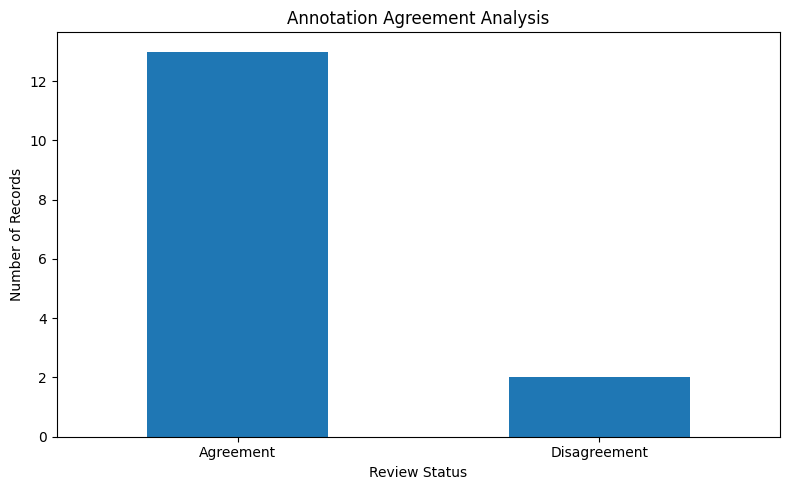

In [9]:
# Count agreement and disagreement records

agreement_summary = df["Agreement"].value_counts()

agreement_summary.index = [
    "Agreement" if value else "Disagreement"
    for value in agreement_summary.index
]

# Create a bar chart
agreement_summary.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Annotation Agreement Analysis")
plt.xlabel("Review Status")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [10]:
# Add columns for manual quality review

df["Review_Status"] = "Pending"
df["Final_Label"] = "Pending"

# Display the records requiring review
df.loc[
    df["Agreement"] == False,
    ["Text", "Annotator_1", "Annotator_2",
     "Review_Status", "Final_Label"]
]

,Text,Annotator_1,Annotator_2,Review_Status,Final_Label
1,The service was very disappointing.,Negative,Positive,Pending,Pending
10,The packaging was beautiful.,Positive,Neutral,Pending,Pending


In [11]:
# Example: review the second record in the dataset

df.loc[1, "Review_Status"] = "Reviewed"

# Example correction after human verification
df.loc[1, "Final_Label"] = "Negative"

df.head()

,Text,Annotator_1,Annotator_2,Agreement,Review_Status,Final_Label
0,I absolutely love this product.,Positive,Positive,True,Pending,Pending
1,The service was very disappointing.,Negative,Positive,False,Reviewed,Negative
2,The delivery was quick.,Positive,Positive,True,Pending,Pending
3,The product is terrible.,Negative,Negative,True,Pending,Pending
4,I am happy with my purchase.,Positive,Positive,True,Pending,Pending


In [12]:

# Save the complete comparison dataset

df.to_csv(
    "Annotation_Quality_Results.csv",
    index=False
)

# Save the quality report separately
quality_report.to_csv(
    "Annotation_Quality_Report.csv",
    index=False
)

print("Both files have been saved successfully!")

Both files have been saved successfully!


In [13]:
# Download the annotation results

from google.colab import files

files.download("Annotation_Quality_Results.csv")
files.download("Annotation_Quality_Report.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
print("ANNOTATION QUALITY CHECKER")
print("--------------------------")

print("Total Records:", total_records)
print("Agreement:", agreed_records)
print("Disagreement:", total_records - agreed_records)

print(
    "Agreement Percentage:",
    round(agreement_percentage, 2), "%"
)

print("Cohen's Kappa:", round(kappa_score, 3))

print("\nProject completed successfully!")

ANNOTATION QUALITY CHECKER
--------------------------
Total Records: 15
Agreement: 13
Disagreement: 2
Agreement Percentage: 86.67 %
Cohen's Kappa: 0.767

Project completed successfully!
